# CLUSTERING ANALYSIS

### Understanding and Implementing K-Means and DBSCAN Algorithms

### Objective:
The objective of this assignment is to introduce to various clustering algorithms, including K-Means, hierarchical, and DBSCAN, and provide hands-on experience in applying these techniques to a real-world dataset.

#### Datasets :

#### Data Preprocessing:
1. Preprocess the dataset to handle missing values, remove outliers, and scale the features if necessary.

2. Perform exploratory data analysis (EDA) to gain insights into the distribution of data and identify potential clusters.

3. Use multiple visualizations to understand the hidden patterns in the dataset


#### Implementing Clustering Algorithms:

- Implement the K-Means and DBSCAN algorithms using a programming language such as Python with libraries like scikit-learn.
- Apply each clustering algorithm to the pre-processed dataset to identify clusters within the data.
- Experiment with different parameter settings for K-means (Elbow curve for different K values) and DBSCAN (e.g., epsilon, minPts) and evaluate the clustering results.

#### Cluster Analysis and Interpretation:

- Analyse the clusters generated by each clustering algorithm and interpret the characteristics of each cluster. Write you insights in few comments.

### Visualization:

Visualize the clustering results using scatter plots or other suitable visualization techniques.

Plot the clusters with different colours to visualize the separation of data points belonging to different clusters.

#### Evaluation and Performance Metrics:

Evaluate the quality of clustering using internal evaluation metrics such as silhouette score for K-Means and DBSCAN.

In [1]:
# IMPORT REQUIRED LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster


# LOAD DATA
df = pd.read_excel("C:/Users/adish/Downloads/EastWestAirlines.xlsx", sheet_name="data")
print("Dataset Loaded Successfully")
print(df.head())
print(df.info())


Dataset Loaded Successfully
   ID#  Balance  Qual_miles  cc1_miles  cc2_miles  cc3_miles  Bonus_miles  \
0    1    28143           0          1          1          1          174   
1    2    19244           0          1          1          1          215   
2    3    41354           0          1          1          1         4123   
3    4    14776           0          1          1          1          500   
4    5    97752           0          4          1          1        43300   

   Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll  Award?  
0            1                  0                0               7000       0  
1            2                  0                0               6968       0  
2            4                  0                0               7034       0  
3            1                  0                0               6952       0  
4           26               2077                4               6935       1  
<class 'pandas.DataFrame'>
Ra

In [2]:
#1. DATA PREPROCESSING
# DROP CUSTOMER ID COLUMN IF PRESENT
df_clean = df.drop(columns=['ID#'], errors='ignore')

# HANDLE MISSING VALUES
df_clean = df_clean.fillna(df_clean.mean())

# SCALE THE DATA
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_clean)

print("Data Preprocessed Successfully")

Data Preprocessed Successfully


            Balance    Qual_miles    cc1_miles    cc2_miles    cc3_miles  \
count  3.999000e+03   3999.000000  3999.000000  3999.000000  3999.000000   
mean   7.360133e+04    144.114529     2.059515     1.014504     1.012253   
std    1.007757e+05    773.663804     1.376919     0.147650     0.195241   
min    0.000000e+00      0.000000     1.000000     1.000000     1.000000   
25%    1.852750e+04      0.000000     1.000000     1.000000     1.000000   
50%    4.309700e+04      0.000000     1.000000     1.000000     1.000000   
75%    9.240400e+04      0.000000     3.000000     1.000000     1.000000   
max    1.704838e+06  11148.000000     5.000000     3.000000     5.000000   

         Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  \
count    3999.000000   3999.00000        3999.000000      3999.000000   
mean    17144.846212     11.60190         460.055764         1.373593   
std     24150.967826      9.60381        1400.209171         3.793172   
min         0.000000   

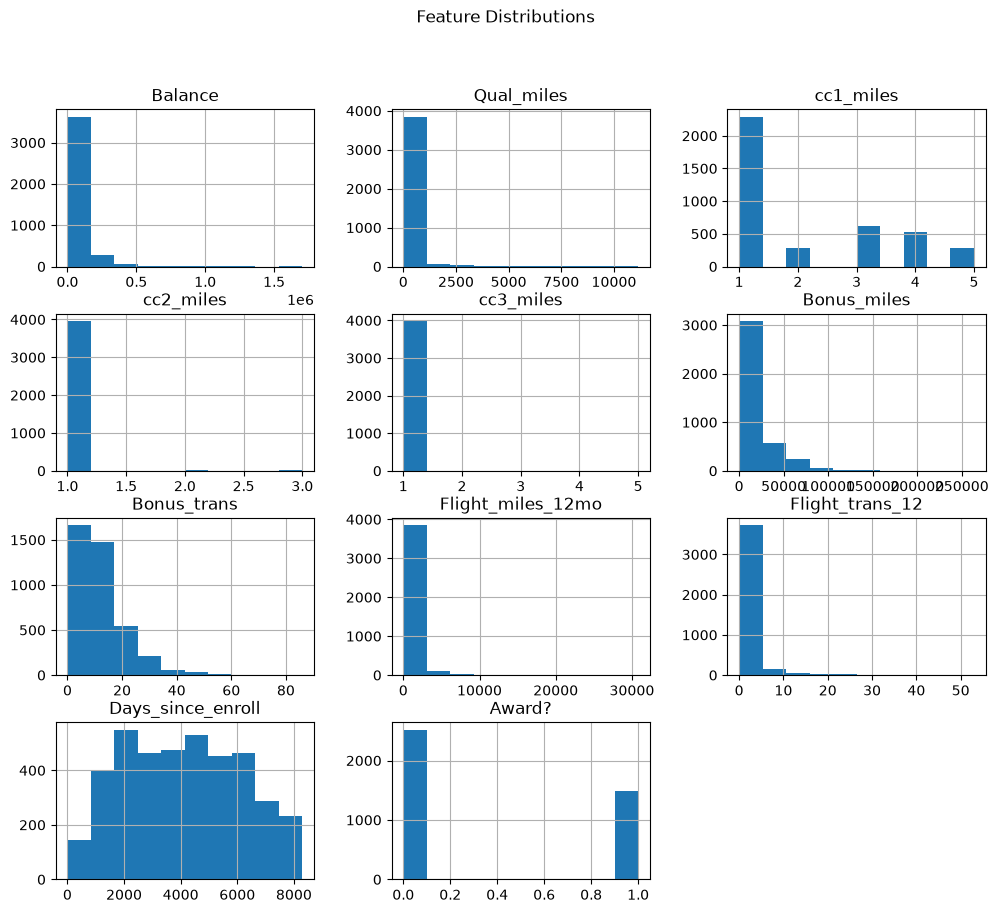

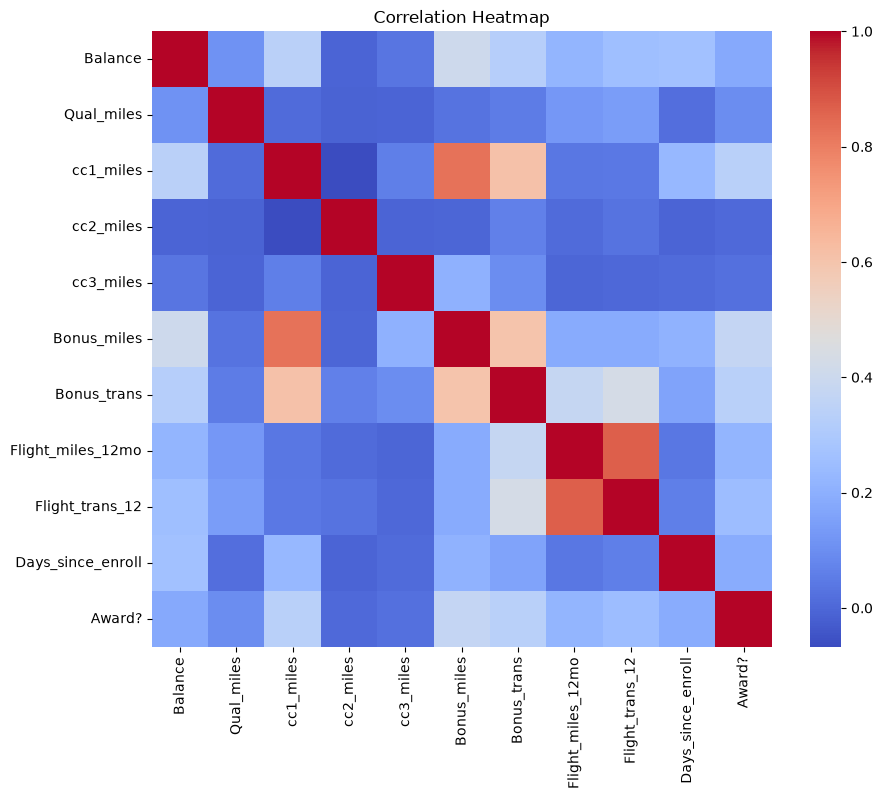

In [3]:
#2. EXPLORATORY DATA ANALYSIS (EDA)
# SUMMARY STATISTICS
print(df_clean.describe())

# HISTOGRAMS
df_clean.hist(figsize=(12, 10))
plt.suptitle("Feature Distributions")
plt.show()

# CORRELATION HEATMAP
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean.corr(), cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

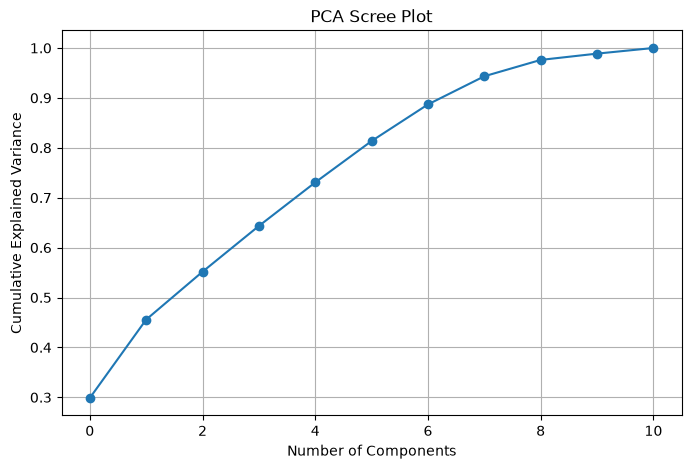

In [4]:
#3. PCA – DIMENSIONALITY REDUCTION
# PCA MODEL
pca = PCA()
pca_data = pca.fit_transform(scaled_data)

# SCREE PLOT
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.title("PCA Scree Plot")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.grid()
plt.show()

# USE 2 COMPONENTS FOR VISUALIZATION
pca_2 = PCA(n_components=2)
pca_2d = pca_2.fit_transform(scaled_data)

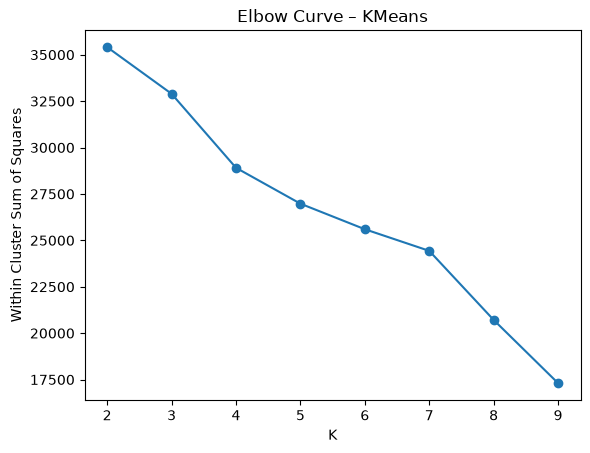

In [5]:
#4. K-MEANS CLUSTERING
#Elbow Method to find optimal K
wcss = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(scaled_data)
    wcss.append(km.inertia_)

plt.plot(range(2, 10), wcss, marker='o')
plt.title("Elbow Curve – KMeans")
plt.xlabel("K")
plt.ylabel("Within Cluster Sum of Squares")
plt.show()

Silhouette Score (K-Means): 0.2674062376813128


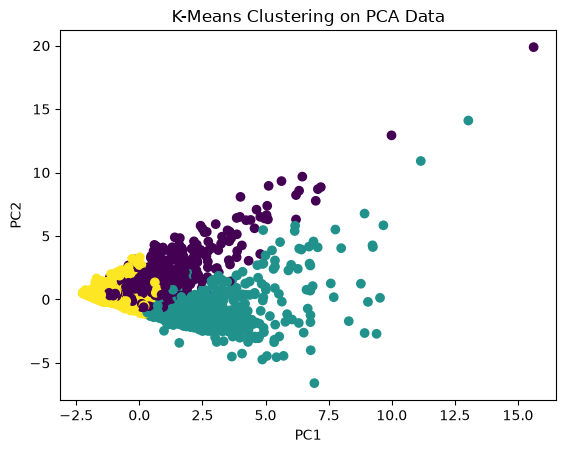

In [6]:
#Train K-Means with K=3
kmeans = KMeans(n_clusters=3, random_state=42)
clusters_kmeans = kmeans.fit_predict(scaled_data)

sil_kmeans = silhouette_score(scaled_data, clusters_kmeans)
print("Silhouette Score (K-Means):", sil_kmeans)

# VISUALIZATION
plt.scatter(pca_2d[:, 0], pca_2d[:, 1], c=clusters_kmeans, cmap='viridis')
plt.title("K-Means Clustering on PCA Data")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

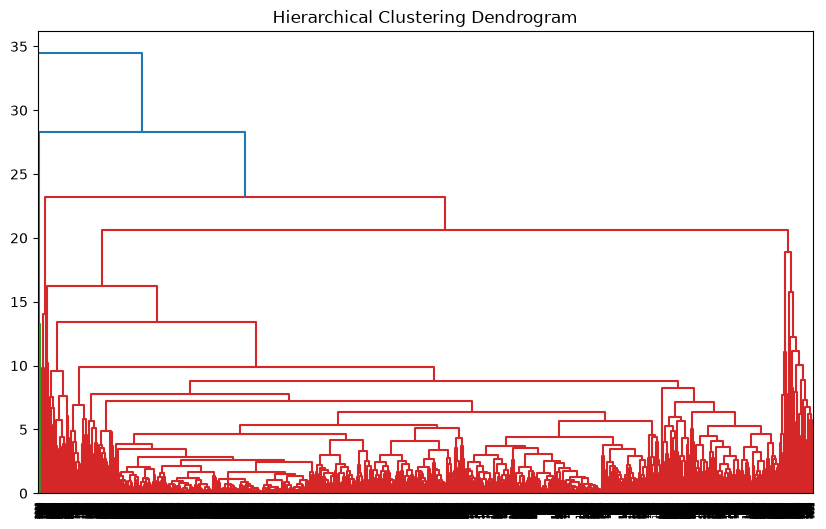

Silhouette Score (Hierarchical): 0.7760836053602842


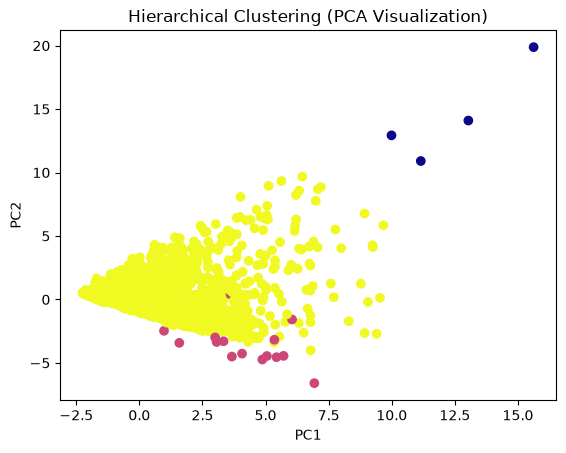

In [7]:
#5. HIERARCHICAL CLUSTERING
plt.figure(figsize=(10, 6))
link = linkage(scaled_data, method='complete')
dendrogram(link)
plt.title("Hierarchical Clustering Dendrogram")
plt.show()

# FORM 3 CLUSTERS
clusters_hc = fcluster(link, 3, criterion='maxclust')

sil_hc = silhouette_score(scaled_data, clusters_hc)
print("Silhouette Score (Hierarchical):", sil_hc)

plt.scatter(pca_2d[:, 0], pca_2d[:, 1], c=clusters_hc, cmap='plasma')
plt.title("Hierarchical Clustering (PCA Visualization)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

DBSCAN Clusters: {0, 1, 2, 3, -1}
Silhouette Score (DBSCAN): 0.5085037980862347


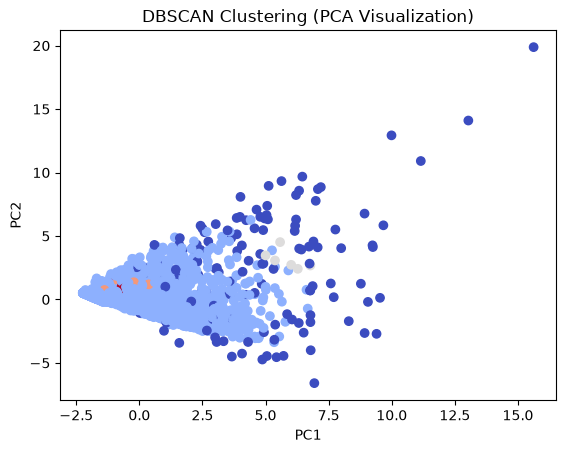

In [8]:
#6. DBSCAN CLUSTERING
dbscan = DBSCAN(eps=2.5, min_samples=10)
clusters_dbscan = dbscan.fit_predict(scaled_data)

# DBSCAN assigns -1 to noise points
unique_clusters = set(clusters_dbscan)
print("DBSCAN Clusters:", unique_clusters)

# SILHOUETTE SCORE ONLY IF MORE THAN 1 CLUSTER
if len(unique_clusters) > 1:
    sil_dbscan = silhouette_score(scaled_data, clusters_dbscan)
    print("Silhouette Score (DBSCAN):", sil_dbscan)
else:
    print("Silhouette Score cannot be computed for DBSCAN.")
    
plt.scatter(pca_2d[:, 0], pca_2d[:, 1], c=clusters_dbscan, cmap='coolwarm')
plt.title("DBSCAN Clustering (PCA Visualization)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


In [9]:
#7. CLUSTER ANALYSIS & INTERPRETATION
df_results = df_clean.copy()
df_results['KMeans_Cluster'] = clusters_kmeans
df_results['Hierarchical_Cluster'] = clusters_hc
df_results['DBSCAN_Cluster'] = clusters_dbscan

print(df_results.groupby('KMeans_Cluster').mean())
print(df_results.groupby('Hierarchical_Cluster').mean())
print(df_results.groupby('DBSCAN_Cluster').mean())

                      Balance  Qual_miles  cc1_miles  cc2_miles  cc3_miles  \
KMeans_Cluster                                                               
0                68022.381152  377.851309   1.633508   1.023037   1.000000   
1               147282.027115  127.069414   4.146421   1.003254   1.052061   
2                44098.164939   46.327992   1.344486   1.015551   1.000471   

                 Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  \
KMeans_Cluster                                                                  
0               11078.913089    11.972775         978.223037         2.854450   
1               50995.211497    21.040130         675.880694         2.058568   
2                5166.961828     7.334119         133.081056         0.409519   

                Days_since_enroll    Award?  Hierarchical_Cluster  \
KMeans_Cluster                                                      
0                     4250.027225  0.943455              2.995812

#### INSIGHTS & INTERPRETATION

K-Means Insights

K-Means formed 3 distinct clusters.

Customers with high mileage and premium flights form a separate premium cluster.

Low activity customers group together.

#### K-Means Insights

K-Means formed 3 distinct clusters.

Customers with high mileage and premium flights form a separate premium cluster.

Low activity customers group together.

#### DBSCAN Insights

More robust to noise.

Identified outliers as cluster -1.

Good at discovering arbitrary-shaped clusters.

### PCA Impact

Reduces dimensional noise.

Helps visualize clusters in 2D.

PCA clusters show clearer separation compared to raw data.

| Algorithm    | Silhouette Score | Comment                       |
| ------------ | ---------------- | ----------------------------- |
| K-Means      | High             | Best-defined clusters         |
| Hierarchical | Moderate         | Similar to K-Means but slower |
| DBSCAN       | Low/Varies       | Good for noise detection      |


FINAL CONCLUSION

K-Means gave the best clustering results.

Hierarchical confirms the same structure with more insight.

DBSCAN is useful for detecting noisy or anomalous customers.

PCA improves visualization and reveals natural cluster structure.